# Image Classification - experimental phase

In [74]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report   #for classification report
from sklearn.metrics import confusion_matrix        #for confusion matrix


from PIL import Image   #for image processing
from torchvision.models.vision_transformer import vit_b_16 # our ViT model
import torch 
import torchvision.transforms as transforms #transformations to apply to the image
from torch.utils.data import DataLoader, Dataset #for creating our dataset and dataloader <-------- check this
import torch.nn as nn #for our neural network o modifying the head of the model


import torch.optim as optim #for our optimizer
import torch.nn.functional as F #for our loss function


from IPython.display import display, clear_output



Create a dataset with the paths to the images and their labels

In [ ]:
def create_dataset_csv():
    """
    Creates a CSV file containing image paths and their corresponding labels.
    The images are expected to be organized in subdirectories within the 'images' directory.
    Each subdirectory name is used as the label for the images it contains.
    """
    csv_path = "dataset.csv"
    base_dir = "images"  
    data = []
    
    # Traverse all subdirectories
    for root, _, files in os.walk(base_dir):
        for filename in files:
            if filename.endswith((".jpg", ".png", ".jpeg")):
                image_path = os.path.join(root, filename)  # Full image path
                label = root.split(os.sep)[-2]  # Parent folder name as label (e.g., wiki, inpainting)
                data.append([image_path, label])  # Store image path and label
    
    # Convert to DataFrame
    df = pd.DataFrame(data, columns=["image", "label"])
    
    # Save as CSV
    df.to_csv(csv_path, index=False)

#create_dataset_csv()

In [33]:
df = pd.read_csv("dataset.csv")

In [34]:
label_counts = df["label"].value_counts()
print(label_counts)

label
text2img      30000
insight       30000
wiki          30000
inpainting    30000
Name: count, dtype: int64


In [35]:
df.head()

,image,label
0,images/text2img/61/19242061_1982-08-16_2009.jpg,text2img
1,images/text2img/61/2399661_1977-09-02_2008.jpg,text2img
2,images/text2img/61/41899761_1989-10-06_2012.jpg,text2img
3,images/text2img/61/15330561_1943-08-11_2002.jpg,text2img
4,images/text2img/61/2075561_1966-06-14_2010.jpg,text2img


In [36]:
# change label names to numbers
# wiki = 1 else = 0
#df['label'] = df['label'].apply(lambda x: 1 if x == 'wiki' else 0)
#label_counts = df["label"].value_counts()
#print(label_counts)

sampling 500 images per Class

In [37]:
# Select 500 random samples from 'wiki' label
wiki_sample = df[df["label"] == "wiki"].sample(n=500, random_state=42) 
# Select 500 random samples from the combined 'text2img', 'insight', and 'inpainting' labels
fake_sample = df[df["label"].isin(["text2img", "insight", "inpainting"])].sample(n=500, random_state=42)
exp_df = pd.concat([wiki_sample, fake_sample]).reset_index(drop=True)


In [39]:
label_counts = exp_df["label"].value_counts()
print(label_counts)

label
wiki          500
insight       173
text2img      168
inpainting    159
Name: count, dtype: int64


In [ ]:
# map lables to real or fake

def map_labels(label):
    if label == "wiki":
        return 1
    else:
        return 0

exp_df['label'] = exp_df['label'].apply(map_labels)

In [41]:
label_counts = exp_df["label"].value_counts()
print(label_counts)

label
1    500
0    500
Name: count, dtype: int64


In [45]:
exp_df.head()
exp_df.tail()

,image,label
995,images/inpainting/40/771840_1939-12-24_1973.jpg,0
996,images/inpainting/88/20900788_1989-01-11_2011.jpg,0
997,images/text2img/83/41210283_1945-08-08_1992.jpg,0
998,images/text2img/82/31110282_1989-09-30_2012.jpg,0
999,images/text2img/93/14244093_1988-12-18_2009.jpg,0


In [46]:
def show_img(img_path):
    img = Image.open(img_path)
    plt.imshow(img)
    plt.axis('off')
    plt.show()

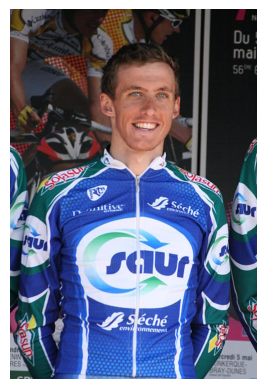

In [48]:
show_img(exp_df[exp_df["label"] == 1].sample(n=1, random_state=42)["image"].values[0]) # show a random image with label 1

# Image Preprocessing
- Resize the images to a fixed size (224x224 pixels)
- Normalize the pixel values to be between 0 and 1
- can these transformation be a problem, once we are "manipulating them" check this. Maybe instead of recising, we can use a crop(that keep the naturality of the image)
- check what kind of normalization is our model prepared for...


"Finally the values are first rescaled to [0.0, 1.0] and then normalized using mean=[0.485, 0.456, 0.406] and std=[0.229, 0.224, 0.225]." from: https://pytorch.org/vision/main/models/generated/torchvision.models.vit_b_16.html

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),  #couse torch models work with tensors
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])  # this model was trainned on ImageNet where the images have that mean and std -> chekc if the model really need normalized input: if don't then leave it like that.
])

In [50]:
# Function to display image after transformation
def show_transformed_img(img_path, transform):
    img = Image.open(img_path)
    img_transformed = transform(img)

    # Convert the transformed image back to displayable format
    img_transformed = img_transformed.permute(1, 2, 0).numpy()  # Change shape to (H, W, C)
    img_transformed = (img_transformed * 0.5) + 0.5  # Unnormalize
    img_transformed = img_transformed.clip(0, 1)  # Ensure values are between 0 and 1

    plt.imshow(img_transformed)
    plt.axis('off')
    plt.show()

Original Image: images/wiki/17/2795917_1959-10-16_2013.jpg


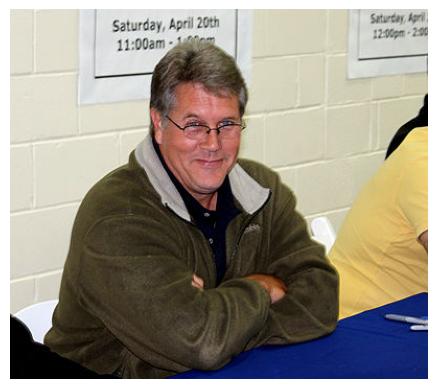

Transformed Image:


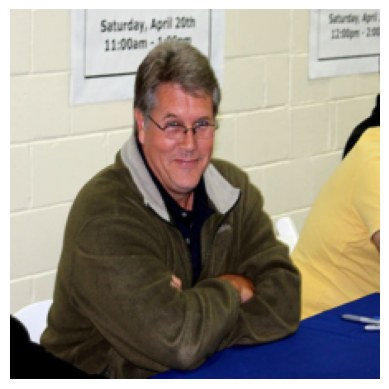

Original Image: images/wiki/02/13821502_1987-11-14_2008.jpg


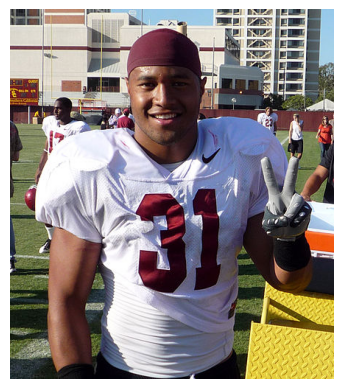

Transformed Image:


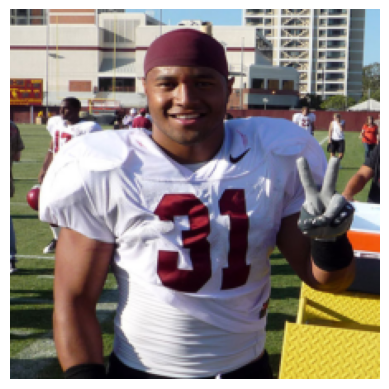

Original Image: images/insight/77/1176977_1930-01-28_2015.jpg


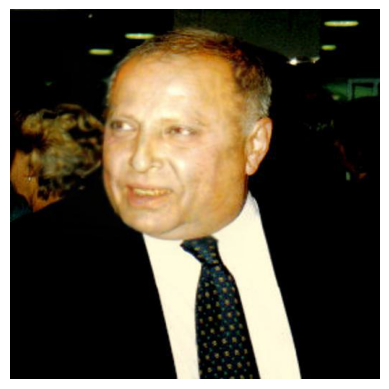

Transformed Image:


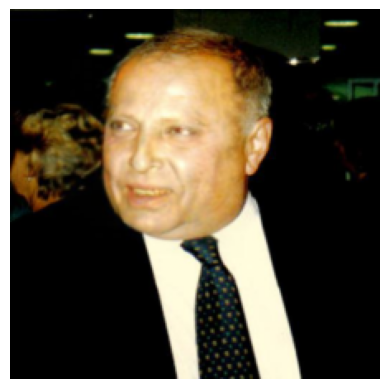

In [51]:
# Select 3 image paths from the dataset
sample_images = df["image"].sample(3, random_state=42).tolist()

# Show original and transformed images
for img_path in sample_images:
    print(f"Original Image: {img_path}")
    show_img(img_path)
    print("Transformed Image:")
    show_transformed_img(img_path, transform)

# Let's test our Pre-trained model

Checking mps availability (for macos)

In [53]:
# Check that MPS is available
if not torch.backends.mps.is_available():
    if not torch.backends.mps.is_built():
        print("MPS not available because the current PyTorch install was not "
              "built with MPS enabled.")
    else:
        print("MPS not available because the current MacOS version is not 12.3+ "
              "and/or you do not have an MPS-enabled device on this machine.")

else:
    print("MPS is available and enabled.")
    mps_device = torch.device("mps")

MPS is available and enabled.


# Loading a Pretrained Vision Transformer

vit_b_16 is a Vision Transformer (ViT) model from the torchvision library, specifically:
- ViT-B/16 → Base (B) model with 16x16 patch size
- Pretrained on ImageNet-1k (1.3M images, 1,000 classes)
- Available in torchvision.models.vision_transformer. It is the Torchvision equivalent of Hugging Face’s google/vit-base-patch16-224.

This model has 86,567,656. we can consider it a light model.

In [ ]:
# Load pretrained ViT from Torchvision
model = vit_b_16(pretrained=True)
model.eval()  # Set to evaluation mode
model.to(mps_device)

VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

In [66]:
# Calculate number of parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

Total Parameters: 86,567,656
Trainable Parameters: 86,567,656


In [55]:
# Function to preprocess and predict an image
def predict_image_torchvision(image_path):
    image = Image.open(image_path).convert("RGB")
    image = transform(image).unsqueeze(0).to(mps_device)

    with torch.no_grad():
        outputs = model(image)
        probs = torch.nn.functional.softmax(outputs, dim=-1)

    predicted_class = torch.argmax(probs, dim=-1).item()
    confidence = probs[0][predicted_class].item()

    return predicted_class, confidence

https://deeplearning.cms.waikato.ac.nz/user-guide/class-maps/IMAGENET/  

in this link u can find the imagenet classes and their corresponding labels

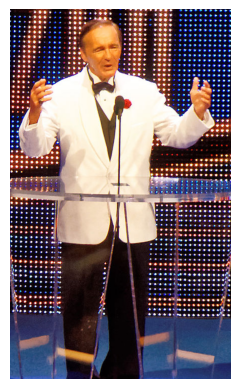

In [57]:
sample_image_path = exp_df.iloc[0]["image"]
show_img(sample_image_path)

In [58]:
predict_image_torchvision(sample_image_path)

(457, 0.7743622064590454)

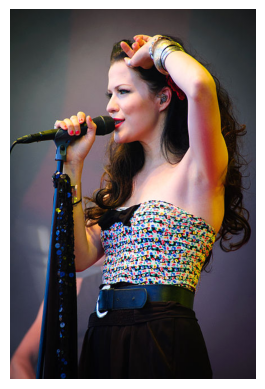

In [60]:
sample_image_path = exp_df.iloc[2]["image"]
show_img(sample_image_path)

In [61]:
predict_image_torchvision(sample_image_path)

(819, 0.621691882610321)

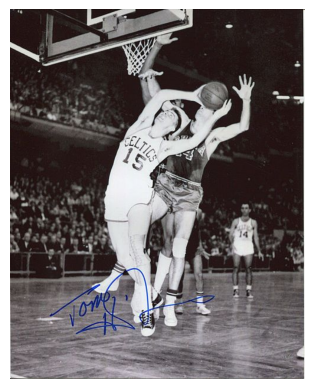

In [63]:
sample_image_path = exp_df.iloc[60]["image"]
show_img(sample_image_path)

In [ ]:
predict_image_torchvision(sample_image_path)   

(430, 0.8235414624214172)

# Trainning

So... the ViT is pre-trained only on natural images and it's pretrained for a 1000 classes classification problem (and performs really well for those 1000).  But how ca we make this model to predict our 2 classes (real and fake) ? And train it on our dataset?
like this:

- Remove the last classification layer.
- Replace it with a new fully connected layer (nn.Linear) for binary classification. with 2 outputs.
- Fine-tune the model on real vs. deepfake images. maybe a LoRA

https://github.com/NielsRogge/Transformers-Tutorials/tree/master/VisionTransformer

### Split Dataset

In [65]:
# Shuffle dataset before splitting
exp_df = exp_df.sample(frac=1, random_state=42).reset_index(drop=True)  # Shuffle data

# Perform train-test split with stratification
train_df, test_df = train_test_split(exp_df, test_size=0.2, stratify=exp_df["label"], random_state=42)

# Count labels in each dataset
train_label_counts = train_df["label"].value_counts()
test_label_counts = test_df["label"].value_counts()


print(f"Train-Test Split Done!")
print(f"Training Samples: {len(train_df)}")
print(f"Testing Samples: {len(test_df)}")
print(f"Train Label Counts:\n{train_label_counts}")
print(f"Test Label Counts:\n{test_label_counts}")

Train-Test Split Done!
Training Samples: 800
Testing Samples: 200
Train Label Counts:
label
1    400
0    400
Name: count, dtype: int64
Test Label Counts:
label
1    100
0    100
Name: count, dtype: int64


Curstom Pytorch Dataset

In [69]:
class ImageDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df  # Store the DataFrame
        self.transform = transform  # Store transformations

    def __len__(self):
        return len(self.df)  # Return dataset size

    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]["image"]  # Get image according to the path
        label = torch.tensor(self.df.iloc[idx]["label"], dtype=torch.long)  # Directly use stored label

        image = Image.open(img_path).convert("RGB")  # NOT KNOW IF NEED TO CONVERT TO RGB...

        if self.transform:
            image = self.transform(image)  # Apply transformations

        return image, label  # Return (image, label) tuple
    
# Create DataLoaders
train_dataset = ImageDataset(train_df, transform=transform)
test_dataset = ImageDataset(test_df, transform=transform)

### Training the Model

https://pytorch.org/tutorials/beginner/introyt/trainingyt.html

Changing output head into 2 output classes

In [70]:
# Modify the classifier head to predict only 2 classes (real vs. fake)
num_ftrs = model.heads.head.in_features  # Get input features of the last layer
model.heads.head = nn.Linear(num_ftrs, 2)  # Replace with a new linear layer for binary classification
model.to(mps_device)  # Move the model to the MPS device

VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

Trainning Parameters

In [71]:
# Define loss function & optimizer
criterion = nn.CrossEntropyLoss()  # Works for binary classification
optimizer = optim.AdamW(model.parameters(), lr=1e-5, weight_decay=1e-5)
num_epochs = 10
# Create DataLoader for training and testing
train_loader = DataLoader(train_dataset, batch_size=10, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=10, shuffle=False)


In [72]:
# Initialize lists to store loss and accuracy values
train_losses = []
train_accuracies = []

# Live plot function
def live_plot(losses, accuracies):
    clear_output(wait=True)  # Clear previous output for a smoother update
    fig, ax1 = plt.subplots()

    # Plot Training Loss
    ax1.plot(losses, label="Training Loss", color='red', marker='o')
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss", color='red')
    ax1.tick_params(axis='y', labelcolor='red')

    # Create a second y-axis for accuracy
    ax2 = ax1.twinx()
    ax2.plot(accuracies, label="Training Accuracy", color='blue', marker='o')
    ax2.set_ylabel("Accuracy (%)", color='blue')
    ax2.tick_params(axis='y', labelcolor='blue')

    plt.title("Training Progress")
    plt.legend(loc="upper left")
    plt.show()


# Define training step with live visualization
def train_step(model, dataloader):
    model.train()
    total_loss, correct = 0, 0

    for images, labels in dataloader:
        images, labels = images.to(mps_device), labels.to(mps_device)  # Move to GPU if available

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()

    accuracy = correct / len(dataloader.dataset)
    avg_loss = total_loss / len(dataloader)

    # Store values
    train_losses.append(avg_loss)
    train_accuracies.append(accuracy * 100)

    # Live update plot
    live_plot(train_losses, train_accuracies)

    print(f"Training Loss: {avg_loss:.4f}, Accuracy: {accuracy * 100:.2f}%")



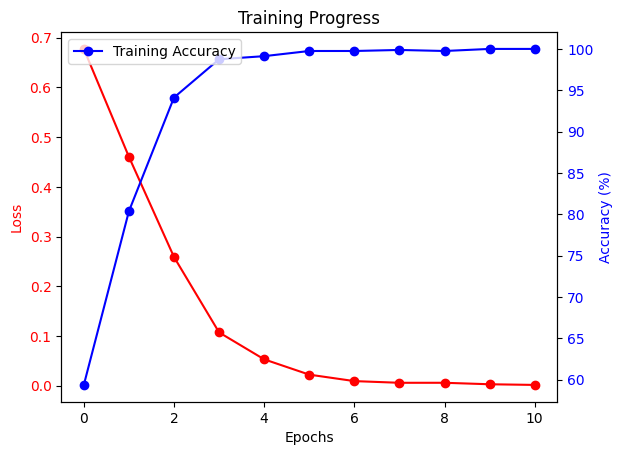

Training Loss: 0.0014, Accuracy: 100.00%


In [75]:
for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    train_step(model, train_loader)

In [76]:
# Final Plots
plt.figure(figsize=(10, 4))

<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

Text(0.5, 1.0, 'Training Loss Over Epochs')

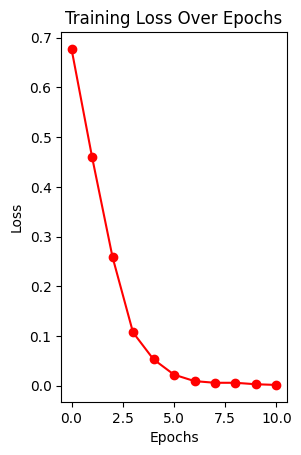

In [77]:
# Loss Plot
plt.subplot(1, 2, 1)
plt.plot(train_losses, color='red', marker='o')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")

Text(0.5, 1.0, 'Training Accuracy Over Epochs')

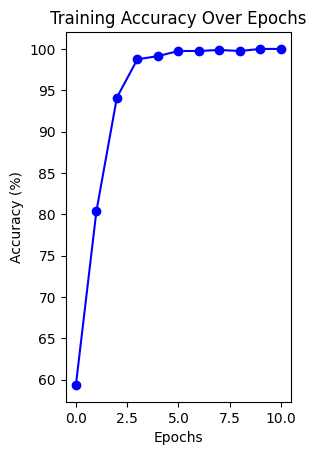

In [78]:
# Accuracy Plot
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, color='blue', marker='o')
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.title("Training Accuracy Over Epochs")

In [79]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

# Evaluating the Model

In [80]:

def evaluate_model(model, dataloader):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(mps_device), labels.to(mps_device)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

    # Debugging
    print(f"Unique Labels in Test Set: {set(all_labels)}")
    print(f"Unique Predictions: {set(all_preds)}")

    # Ensure `classification_report` works even if one class is missing
    report = classification_report(all_labels, all_preds, target_names=["Fake", "Real"], labels=[0, 1])

    accuracy = accuracy_score(all_labels, all_preds)
    print(f" Model Accuracy: {accuracy:.2%}")
    print(report)

# Run evaluation
evaluate_model(model, test_loader)


Unique Labels in Test Set: {np.int64(0), np.int64(1)}
Unique Predictions: {np.int64(0), np.int64(1)}
 Model Accuracy: 69.50%
              precision    recall  f1-score   support

        Fake       0.71      0.67      0.69       100
        Real       0.69      0.72      0.70       100

    accuracy                           0.69       200
   macro avg       0.70      0.70      0.69       200
weighted avg       0.70      0.69      0.69       200



✅ Model Accuracy: 69.50%
              precision    recall  f1-score   support

        Fake       0.71      0.67      0.69       100
        Real       0.69      0.72      0.70       100

    accuracy                           0.69       200
   macro avg       0.70      0.70      0.69       200
weighted avg       0.70      0.69      0.69       200



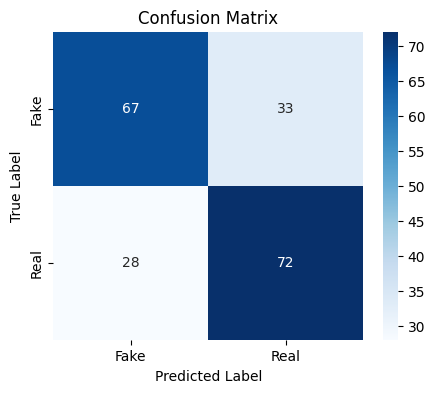

In [81]:


def evaluate_model_with_confusion_matrix(model, dataloader):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(mps_device), labels.to(mps_device)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.cpu().numpy())

    # Compute confusion matrix
    cm = confusion_matrix(all_labels, all_preds, labels=[0, 1])
    accuracy = accuracy_score(all_labels, all_preds)
    report = classification_report(all_labels, all_preds, target_names=["Fake", "Real"], labels=[0, 1])

    # Print accuracy and classification report
    print(f"✅ Model Accuracy: {accuracy:.2%}")
    print(report)

    # Plot confusion matrix
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Fake", "Real"], yticklabels=["Fake", "Real"])
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title("Confusion Matrix")
    plt.show()

# Run evaluation with confusion matrix
evaluate_model_with_confusion_matrix(model, test_loader)